# Opdracht 2 : Voorspel verhuur aantallen


## Teamgegevens

* **teamnaam in kaggle: JAV** 
* **Teamleden met kaggle gebruikersnamen:**
  * Jakub Rebelski (jakubrebelski1)
  * Arda Bagci (Muhammed Arda Bağcı)
  * Vito van Herwerden (Vito van Herwerden)



## Inleiding

In dit project treden wij op als junior data scientists voor CityBike, een aanbieder van deelfietsen. Ons doel is om een voorspellend model te ontwikkelen dat zo nauwkeurig mogelijk het aantal verhuurde fietsen per uur voorspelt, gebaseerd op historische verhuurcijfers, tijdstippen en weersgegevens.

Een sterk voorspellend model kan CityBike gericht helpen bij het slim beheren van de fietsenvloot, zoals het op tijd herverdelen van fietsen en het inplannen van onderhoud. Omdat verkeerde voorspellingen in de praktijk directe gevolgen hebben (zoals lege stations tijdens de spits of juist onnodige kosten door overcapaciteit), vereist deze opdracht een kritische blik op de tijdreeksdata, de gemaakte keuzes en de uiteindelijke betrouwbaarheid van het model.

Dit project vormt tevens onze inzending voor de Kaggle-competitie van de opleiding Applied Data Science & AI. In dit notebook documenteren we ons volledige proces: van de initiële Exploratieve Data Analyse (EDA) en tijdserie-analyse tot het trainen, evalueren en verantwoorden van ons best presterende model.

## Imports
Hier laden we alle benodigde Python-bibliotheken in die we gebruiken voor de data-analyse en het trainen van de modellen die we later nodig gaan hebben.

In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.deterministic import DeterministicProcess
from scipy.signal import periodogram
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.deterministic import CalendarFourier, DeterministicProcess
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

# Data inladen
Voor dit project maken we gebruik van drie bestanden die voor de Kaggle-competitie beschikbaar zijn gesteld. We laden deze direct aan het begin in.


In [124]:
df = pd.read_csv('../Data/train.csv')
df_test = pd.read_csv('../Data/test.csv')
df_submission = pd.read_csv('../Data/sample_submission.csv')

# Hier controleren we of de data correct is ingeladen
df.head()

,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


# 1. Opdracht 1: Exploratieve Data Analyse


## 1.1 Datatypes en basisstatistieken

We beginnen de EDA met een eerste check van de trainingsdata (`train.csv`). Hiervoor hebben we de class `BikeEDA` aangemaakt, zodat we alle stappen van onze analyse netjes op één plek hebben.

In deze eerste stap bekijken we de datatypes, de basisstatistieken van alle kolommen en controleren we of er missende waardes of dubbele rijen in de dataset zitten.

In [125]:
class BikeEDA:
    """Class voor het inspecteren, opschonen en visualiseren van fietsdata."""

    def __init__(self, dataframe):
        """Sla een kopie van de dataset op."""
        self.df = dataframe.copy()

    def inspect_data(self):
        """Toon datatypes, basisstatistieken, missende waardes en duplicaten."""
        print(f"Vorm (rijen, kolommen): {self.df.shape}\n")

        # Datatypes en aantal ingevulde waardes per kolom bekijken
        print("Datatypes:")
        self.df.info()

        # Basisstatistieken van alle kolommen (inclusief tekstkolommen)
        print("\nBasisstatistieken:")
        display(self.df.describe(include="all"))

        # Controleren op missende waardes en dubbele rijen
        missing = self.df.isnull().sum()
        duplicates = self.df.duplicated().sum()
        print(f"Missende waardes per kolom:\n{missing}\n")
        print(f"Aantal dubbele rijen: {duplicates}\n")

In [126]:
eda = BikeEDA(df)
eda.inspect_data()

Vorm (rijen, kolommen): (16637, 8)

Datatypes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16637 entries, 0 to 16636
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date_hour   16637 non-null  object 
 1   holiday     16637 non-null  int64  
 2   weathersit  16637 non-null  int64  
 3   temp        16637 non-null  float64
 4   atemp       16637 non-null  float64
 5   hum         16637 non-null  float64
 6   windspeed   16637 non-null  float64
 7   cnt         16637 non-null  int64  
dtypes: float64(4), int64(3), object(1)
memory usage: 1.0+ MB

Basisstatistieken:


,date_hour,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
unique,16637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2012-11-30 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
std,NaN,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755
min,NaN,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,NaN,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,NaN,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,NaN,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000


Missende waardes per kolom:
date_hour     0
holiday       0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
cnt           0
dtype: int64

Aantal dubbele rijen: 0



## 1.2 Tijdserie-elementen toevoegen

In de vorige stap zagen we dat de kolom `date_hour` nog is opgeslagen als tekst (`object`). Om patronen over de tijd goed te kunnen onderzoeken, zoals spitsuren, weekenden of seizoenen, moeten we deze kolom eerst omzetten naar een echt datum- en tijdformaat (`datetime`).

Hiervoor schrijven we een functie die `date_hour` omzet en er direct een aantal losse tijdelementen uithaalt: het jaar, de maand, de dag van de week, het uur en of het weekend is. Zo kunnen we deze straks makkelijk visualiseren.

In [127]:
def add_time_features(dataframe):
    """Zet date_hour om naar datetime en voeg tijdelementen toe."""
    df_copy = dataframe.copy()
    df_copy["date_hour"] = pd.to_datetime(df_copy["date_hour"])

    df_copy["year"] = df_copy["date_hour"].dt.year
    df_copy["month"] = df_copy["date_hour"].dt.month
    df_copy["day_of_week"] = df_copy["date_hour"].dt.dayofweek
    df_copy["hour"] = df_copy["date_hour"].dt.hour
    df_copy["is_weekend"] = df_copy["day_of_week"].isin([5, 6]).astype(int)

    # Tijdkolom als index zetten en chronologisch sorteren
    df_copy = df_copy.set_index("date_hour").sort_index()
    

    return df_copy

In [128]:
df_eda = add_time_features(df)
df_eda.head()

,holiday,weathersit,temp,atemp,hum,windspeed,cnt,year,month,day_of_week,hour,is_weekend
date_hour,,,,,,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16,2011,1,5,0,1
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40,2011,1,5,1,1
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32,2011,1,5,2,1
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13,2011,1,5,3,1
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1,2011,1,5,4,1


## 1.3 Tijdspatronen visualiseren

Nu we de tijdelementen hebben toegevoegd, plotten we de verhuuraantallen over verschillende tijdschalen. We gebruiken hiervoor lijngrafieken om trends, seizoenen en dagelijkse patronen te laten zien te maken.


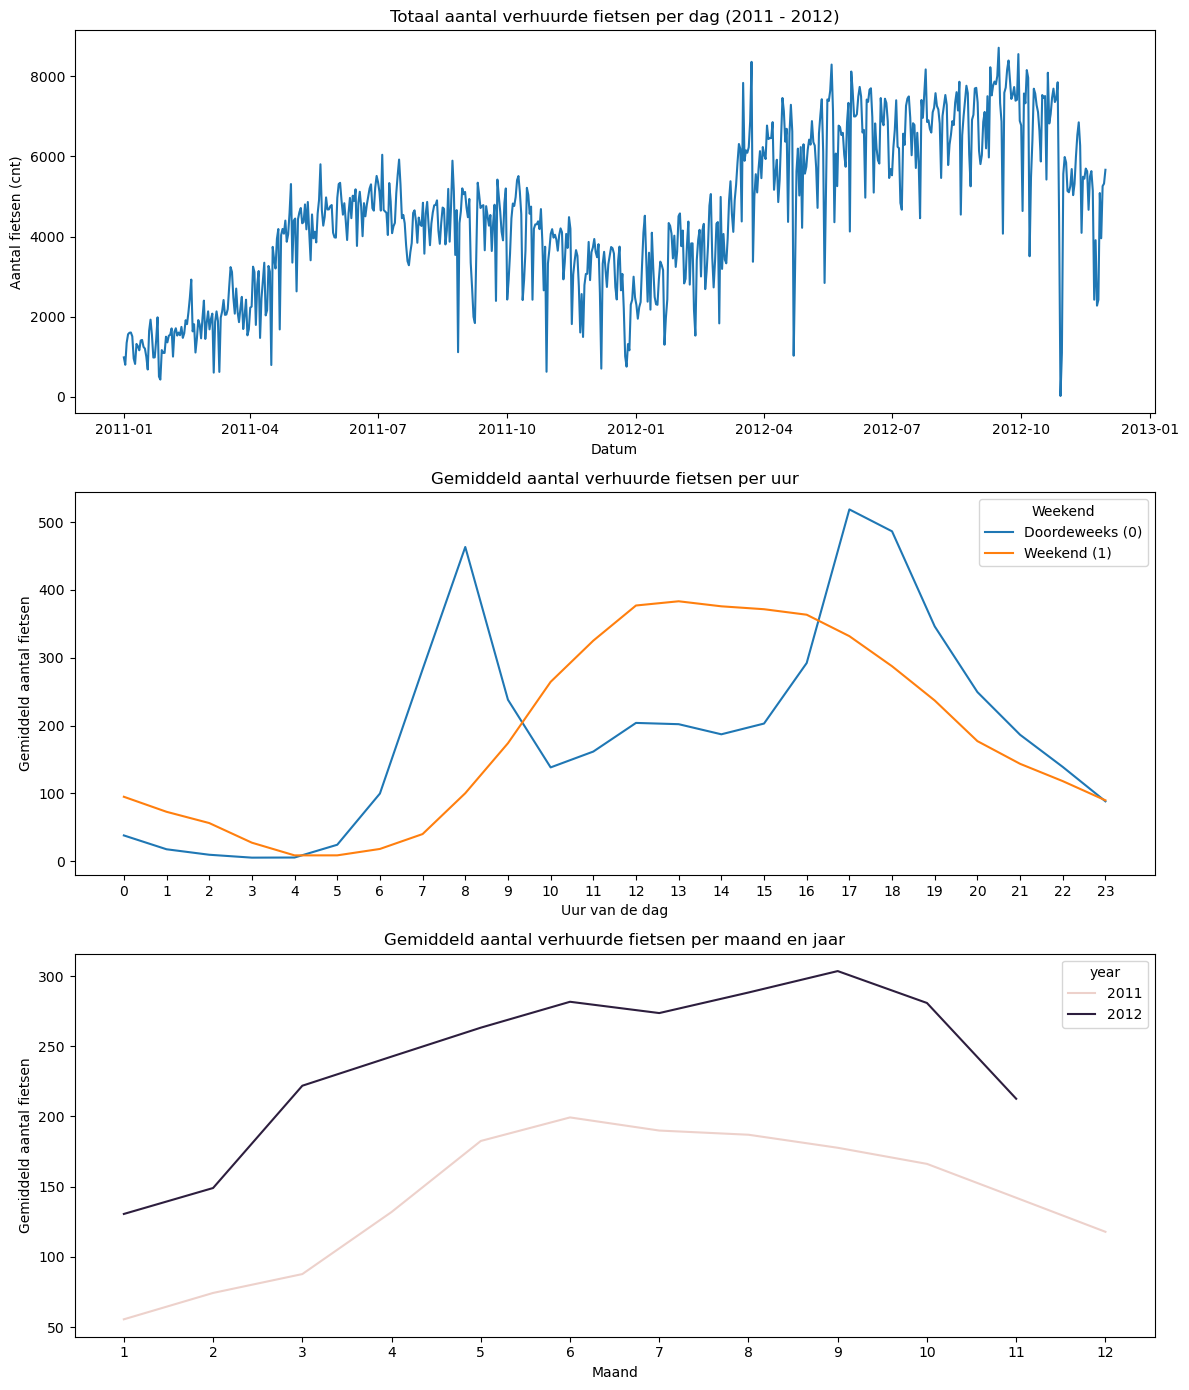

In [129]:
def plot_time_patterns(dataframe):
    """Plot het verloop per dag, per uur (weekend vs. doordeweeks) en per maand."""
    fig, axes = plt.subplots(3, 1, figsize=(12, 14))

    # 1. Dagelijks totaal over de hele periode (resample("D") groepeert per dag)
    daily_cnt = dataframe["cnt"].resample("D").sum()
    axes[0].plot(daily_cnt.index, daily_cnt.values)
    axes[0].set_title("Totaal aantal verhuurde fietsen per dag (2011 - 2012)")
    axes[0].set_xlabel("Datum")
    axes[0].set_ylabel("Aantal fietsen (cnt)")

    # 2. Gemiddelde per uur: doordeweeks en weekend
    sns.lineplot(
        data=dataframe,
        x="hour",
        y="cnt",
        hue="is_weekend",
        ax=axes[1],
        errorbar=None,
    )
    axes[1].set_title("Gemiddeld aantal verhuurde fietsen per uur")
    axes[1].set_xlabel("Uur van de dag")
    axes[1].set_ylabel("Gemiddeld aantal fietsen")
    axes[1].set_xticks(range(0, 24))
    axes[1].legend(title="Weekend", labels=["Doordeweeks (0)", "Weekend (1)"])

    # 3. Gemiddelde per maand, gesplitst per jaar
    sns.lineplot(
        data=dataframe,
        x="month",
        y="cnt",
        hue="year",
        ax=axes[2],
        errorbar=None,
    )
    axes[2].set_title("Gemiddeld aantal verhuurde fietsen per maand en jaar")
    axes[2].set_xlabel("Maand")
    axes[2].set_ylabel("Gemiddeld aantal fietsen")
    axes[2].set_xticks(range(1, 13))

    plt.tight_layout()
    plt.show()


plot_time_patterns(df_eda)


**Observaties tijdspatronen:**
* **Trend:** In 2012 worden er gemiddeld meer fietsen verhuurd dan in 2011. Er vind dus een duidelijke stijgende trend plaats in de data.
* **Seizoenen:** In de warmere maanden (mei t/m oktober) worden er gemiddeld meer fietsen verhuurd dan in de winter.
* **Dagpatroon:** Doordeweeks zijn er twee duidelijke pieken tijdens de ochtend- en avondspits (08:00 en 17:00-18:00). In het weekend ligt de piek juist midden op de dag tussen 12:00 en 16:00.
* **Uitschieter:** Eind oktober 2012 is er een extreme dip richting 0 verhuurde fietsen.

## 1.4 Relaties tussen de features en cnt

Nu bekijken we hoe de andere kolommen samenhangen met het aantal verhuurde fietsen (`cnt`). Voor de numerieke kolommen (`temp`, `atemp`, `hum`, `windspeed`) gebruiken we een Pearson-correlatiematrix en scatterplots. Voor `weathersit` en `holiday` gebruiken we boxplots, omdat dit geen gewone numerieke waardes zijn maar categorieën.


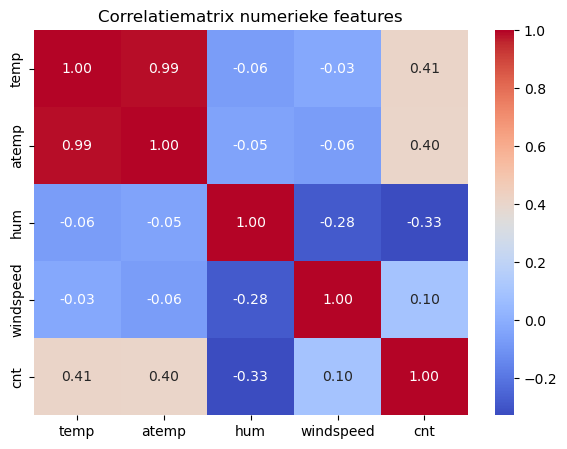

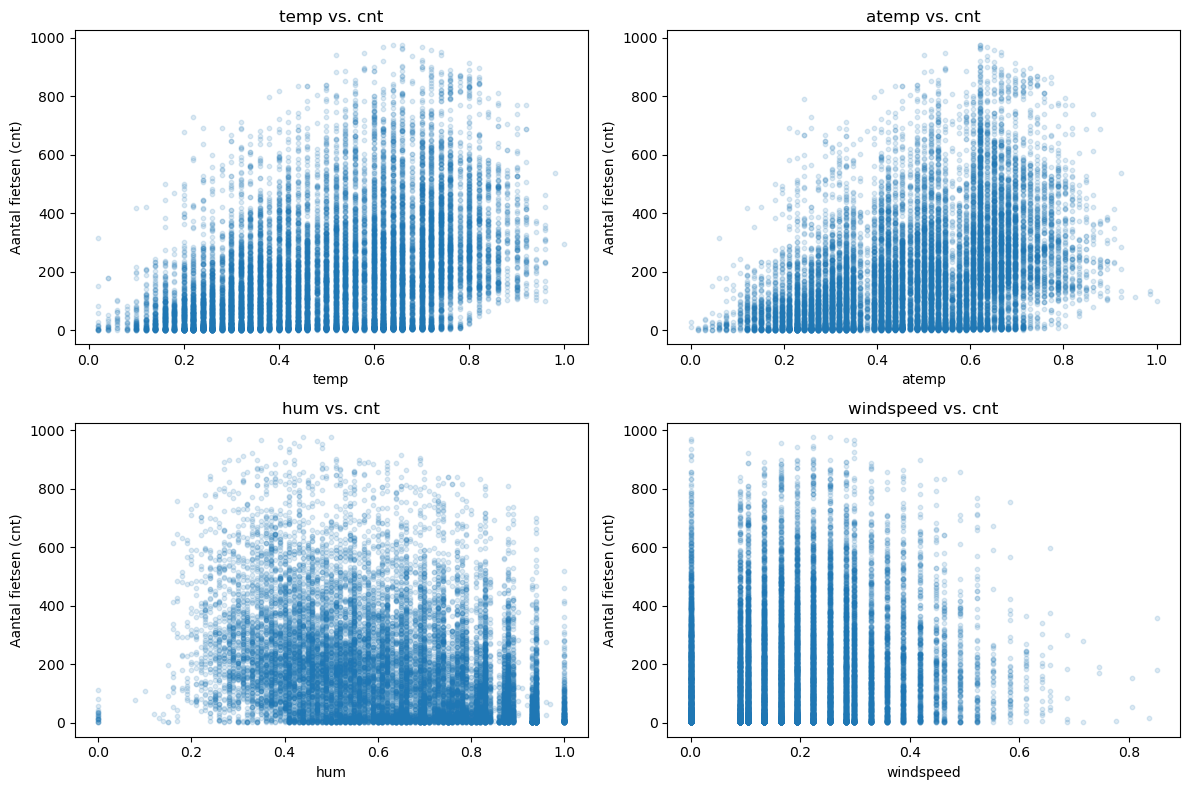

In [130]:
def plot_numeric_relations(dataframe):
    """Plot een correlatiematrix en scatterplots voor numerieke features."""
    num_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]

    # 1. Correlatiematrix (alleen numerieke kolommen)
    plt.figure(figsize=(7, 5))
    corr_matrix = dataframe[num_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlatiematrix numerieke features")
    plt.show()

    # 2. Scatterplots van iedere numerieke feature tegen cnt
    features = ["temp", "atemp", "hum", "windspeed"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    for ax, col in zip(axes.flatten(), features):
        # alpha=0.15 maakt punten transparant zodat drukke plekken zichtbaar zijn
        ax.scatter(dataframe[col], dataframe["cnt"], alpha=0.15, s=10)
        ax.set_title(f"{col} vs. cnt")
        ax.set_xlabel(col)
        ax.set_ylabel("Aantal fietsen (cnt)")

    plt.tight_layout()
    plt.show()


plot_numeric_relations(df_eda)

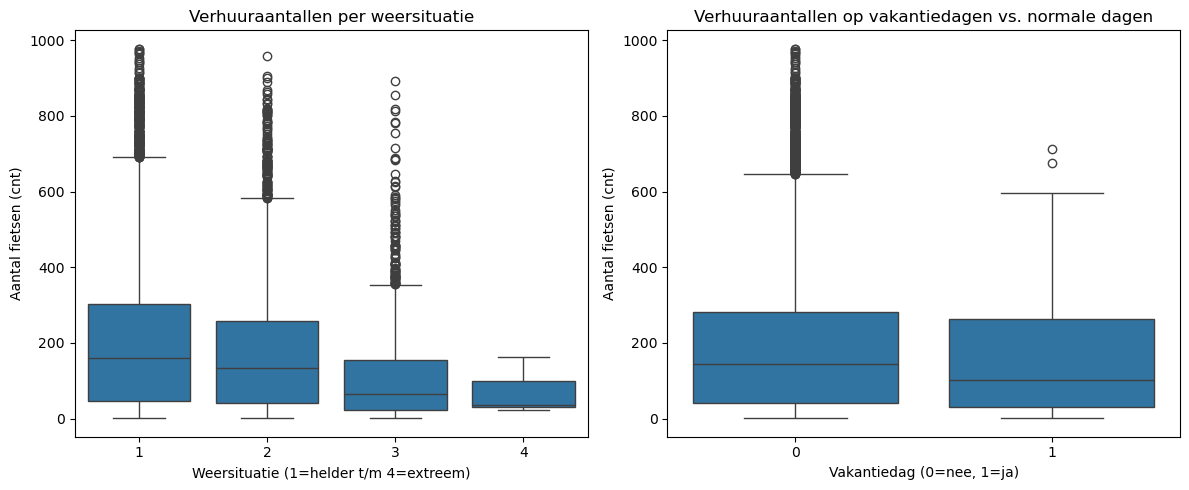

In [131]:
def plot_categorical_relations(dataframe):
    """Plot boxplots voor weathersit en holiday tegen cnt."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.boxplot(data=dataframe, x="weathersit", y="cnt", ax=axes[0])
    axes[0].set_title("Verhuuraantallen per weersituatie")
    axes[0].set_xlabel("Weersituatie (1=helder t/m 4=extreem)")
    axes[0].set_ylabel("Aantal fietsen (cnt)")

    sns.boxplot(data=dataframe, x="holiday", y="cnt", ax=axes[1])
    axes[1].set_title("Verhuuraantallen op vakantiedagen vs. normale dagen")
    axes[1].set_xlabel("Vakantiedag (0=nee, 1=ja)")
    axes[1].set_ylabel("Aantal fietsen (cnt)")

    plt.tight_layout()
    plt.show()


plot_categorical_relations(df_eda)

Uit de correlatiematrix, scatterplots en boxplots vallen een paar dingen op:
- `temp` en `atemp` hebben een correlatie van 0.99 en bevatten dus bijna dezelfde informatie. Beide hebben een positief verband met `cnt` (hoe warmer, hoe meer fietsen er worden verhuurd).
- `hum` heeft een negatief verband met `cnt` (-0.33): bij hogere luchtvochtigheid wordt er minder gefietst. In de scatterplot staan een paar punten op precies 0.0, wat waarschijnlijk meetfouten zijn.
- `windspeed` heeft een lage lineaire correlatie (0.10) en heel veel waardes op precies 0.0, met een gat tot ongeveer 0.09. We verwijderen deze kolom niet direct op basis van de correlatie, maar houden wel rekening met die nullen.
- Bij `weathersit` zakt het aantal verhuurde fietsen duidelijk zodra het weer slechter wordt (van categorie 1 naar 4).
- Op vakantiedagen (`holiday = 1`) ligt de mediaan iets lager dan op gewone dagen en zijn er veel minder hoge pieken.

## 1.5 Data opschonen

Uit de grafieken zagen we een paar opvallende punten, zoals nullen bij `hum` en `windspeed`, en bijna geen datapunten bij `weathersit == 4`. Daarnaast willen we weten of er uren ontbreken in de tijdreeks. We schrijven eerst een functie om deze aantallen precies te tellen, zodat we daarna kunnen bepalen wat we opschonen.

In [132]:
def check_data_issues(dataframe):
    """Tel opvallende waardes en ontbrekende uren in de dataset."""
    # Aantal rijen met 0 bij luchtvochtigheid en windsnelheid
    hum_zero = (dataframe["hum"] == 0).sum()
    wind_zero = (dataframe["windspeed"] == 0).sum()

    # Aantal rijen per weersituatie
    weather_counts = dataframe["weathersit"].value_counts().sort_index()

    # Controleren hoeveel uren er ontbreken
    full_range = pd.date_range(
        start=dataframe.index.min(),
        end=dataframe.index.max(),
        freq="h",
    )
    missing_hours = len(full_range.difference(dataframe.index))

    print(f"Aantal rijen met hum == 0: {hum_zero}")
    print(f"Aantal rijen met windspeed == 0: {wind_zero}")
    print(f"Aantal ontbrekende uren in de tijdlijn: {missing_hours}\n")
    print("Verdeling weathersit:")
    print(weather_counts)


check_data_issues(df_eda)

Aantal rijen met hum == 0: 22
Aantal rijen met windspeed == 0: 2072
Aantal ontbrekende uren in de tijdlijn: 163

Verdeling weathersit:
weathersit
1    11078
2     4207
3     1349
4        3
Name: count, dtype: int64


Op basis van deze aantallen maken we de volgende keuzes voor het opschonen:
- `atemp` halen we weg, omdat deze een correlatie van 0.99 heeft met `temp` en dus bijna dezelfde informatie geeft. Zo voorkomen we overfitting.
- De 22 rijen waar `hum` precies 0 is zijn meetfouten. Deze zetten we om naar `NaN` en vullen we op met het gemiddelde van de uren ervoor en erna.
- `windspeed == 0` komt 2072 keer voor (ruim 12% van de data). Omdat het ook gewoon windstil kan zijn, laten we deze staan.
- `weathersit == 4` komt maar 3 keer voor, wat te weinig is om goed van te leren. Deze voegen we samen met categorie 3 (slecht weer).
- De 163 ontbrekende uren vullen we hier nog niet aan, zodat we geen verzonnen data aan de normale ML-modellen geven. Bij de tijdseriemodellen in opdracht 2 en 3 lossen we dit apart op.

In [133]:
def clean_data(dataframe):
    """Schoon de dataset op: verwijder atemp, fix hum==0 en voeg weathersit 4 samen."""
    df_clean = dataframe.copy()

    # 1. Verwijder atemp vanwege zeer hoge correlatie (0.99) met temp
    if "atemp" in df_clean.columns:
        df_clean = df_clean.drop(columns=["atemp"])

    # 2. Vervang onmogelijke 0-waardes bij luchtvochtigheid en interpoleer
    df_clean["hum"] = df_clean["hum"].replace(0, np.nan).interpolate()

    # 3. Voeg weathersit 4 (slechts 3 rijen) samen met categorie 3
    df_clean["weathersit"] = df_clean["weathersit"].replace(4, 3)

    return df_clean


df_clean = clean_data(df_eda)
print("Nieuwe verdeling weathersit:")
print(df_clean["weathersit"].value_counts().sort_index())
print(f"Aantal rijen met hum == 0 na opschonen: {(df_clean['hum'] == 0).sum()}")

Nieuwe verdeling weathersit:
weathersit
1    11078
2     4207
3     1352
Name: count, dtype: int64
Aantal rijen met hum == 0 na opschonen: 0


## 1.6 Belangrijkste bevindingen EDA

- De trainingsdata bestaat uit 16.637 uurlijkse metingen van januari 2011 t/m november 2012, met 163 ontbrekende uren in de tijdlijn.
- Er is een duidelijke stijgende trend: in 2012 worden er flink meer fietsen verhuurd dan in 2011.
- Het verhuurpatroon hangt sterk af van de tijd: in de zomermaanden wordt er veel meer gefietst dan in de winter, doordeweeks zijn er spitsuren rond 08:00 en 17:00-18:00 uur, en in het weekend ligt de piek tussen 12:00 en 16:00 uur.
- Het weer speelt een grote rol: hogere temperaturen zorgen voor meer verhuur, terwijl hoge luchtvochtigheid en slechter weer (`weathersit`) het aantal verhuurde fietsen verlagen.
- Voor het opschonen hebben we `atemp` verwijderd (0.99 correlatie met `temp`), de 22 nullen bij `hum` geïnterpoleerd en de 3 rijen met `weathersit == 4` samengevoegd met categorie 3.

# 2. Time series feature engineering

## 2.1 Tijdreeks gelijkmatig maken en ontleden

In opdracht 1 zagen we dat er 163 uren missen in de dataset. Voor tijdserie-analyses moeten de tijdstappen gelijkmatig verdeeld zijn. Daarom maken we eerst een gelijkmatige uurlijkse tijdreeks van `cnt` door de ontbrekende uren te interpoleren.

Daarna gebruiken we `seasonal_decompose` om de trend, het seizoenspatroon en de ruis los van elkaar te bekijken. Om de grafiek overzichtelijk te houden, aggregeren we de data hiervoor naar dagelijkse totalen met een wekelijkse periode (`period=7`).

Aantal uren in gelijkmatige tijdreeks: 16800
Aantal ontbrekende waardes: 0


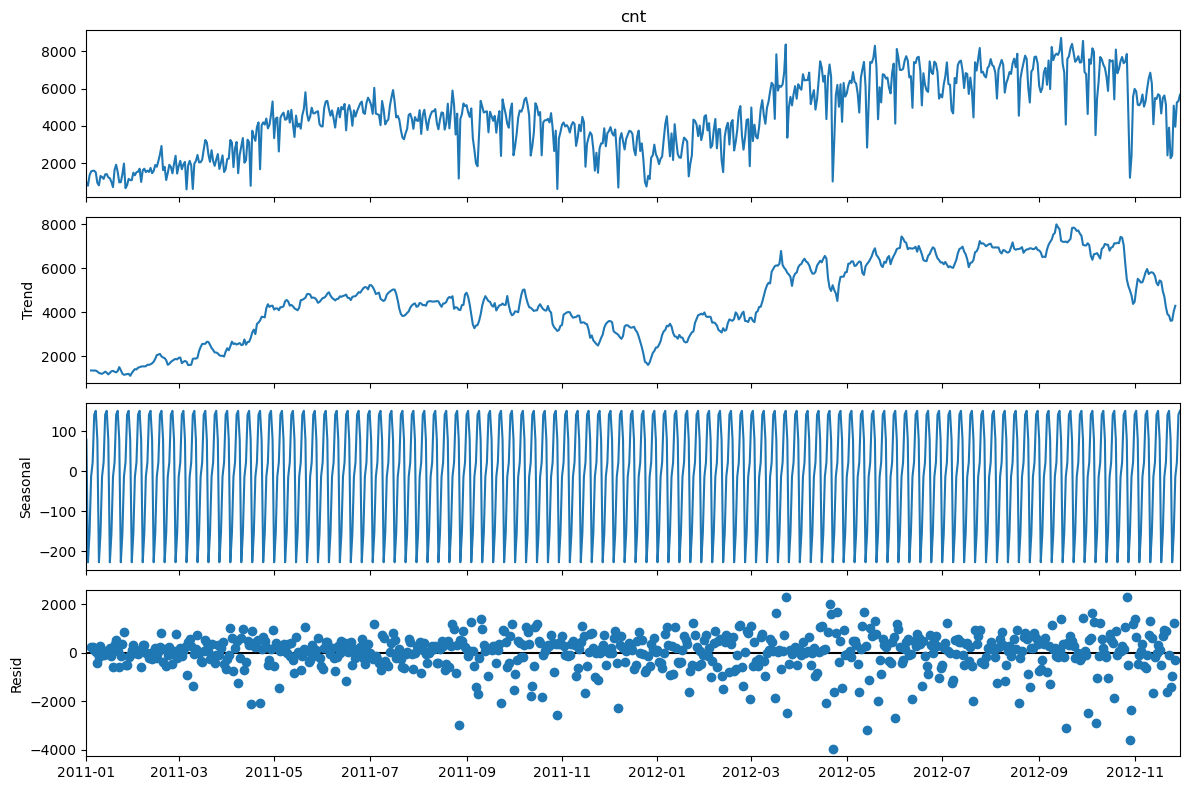

In [134]:
def make_regular_series(dataframe, target_col="cnt"):
    """Maak een gelijkmatige uurlijkse tijdreeks door ontbrekende uren te interpoleren."""
    ts_hourly = dataframe[target_col].asfreq("h").interpolate()
    return ts_hourly


def plot_decomposition(ts_hourly):
    """Ontleed de dagelijkse tijdreeks in trend, seasonal en residual."""
    ts_daily = ts_hourly.resample("D").sum()
    decomposition = seasonal_decompose(ts_daily, model="additive", period=7)

    fig = decomposition.plot()
    fig.set_size_inches(12, 8)
    plt.tight_layout()
    plt.show()


ts_hourly = make_regular_series(df_clean)
print(f"Aantal uren in gelijkmatige tijdreeks: {len(ts_hourly)}")
print(f"Aantal ontbrekende waardes: {ts_hourly.isna().sum()}")

plot_decomposition(ts_hourly)

Uit de decompositie valt het volgende op:
- De tijdreeks bestaat nu uit 16.800 aaneengesloten uren zonder ontbrekende waardes.
- In de trendlijn is zowel de algehele groei van 2011 naar 2012 zichtbaar als de jaarlijkse schommeling (hoger in de zomer, lager in de winter).
- De seizoenscomponent laat een constant wekelijks patroon zien dat schommelt tussen ongeveer -200 en +150 fietsen per dag.
- De residuen liggen rond de 0, met een paar flinke negatieve uitschieters (tot bijna -4000). Dit wijst op dagen waarop externe factoren, zoals slecht weer, de vraag plotseling sterk omlaag drukten.

## 2.2 Onderzoek naar trends

Om de stijgende trend mee te geven aan onze modellen, onderzoeken we met `DeterministicProcess` een lineaire trend (`order=1`) en een kwadratische trend (`order=2`). We plotten beide over het dagelijkse totaal om te zien welke het beste aansluit op de groei en veilig te gebruiken is voor voorspellingen in de toekomst.

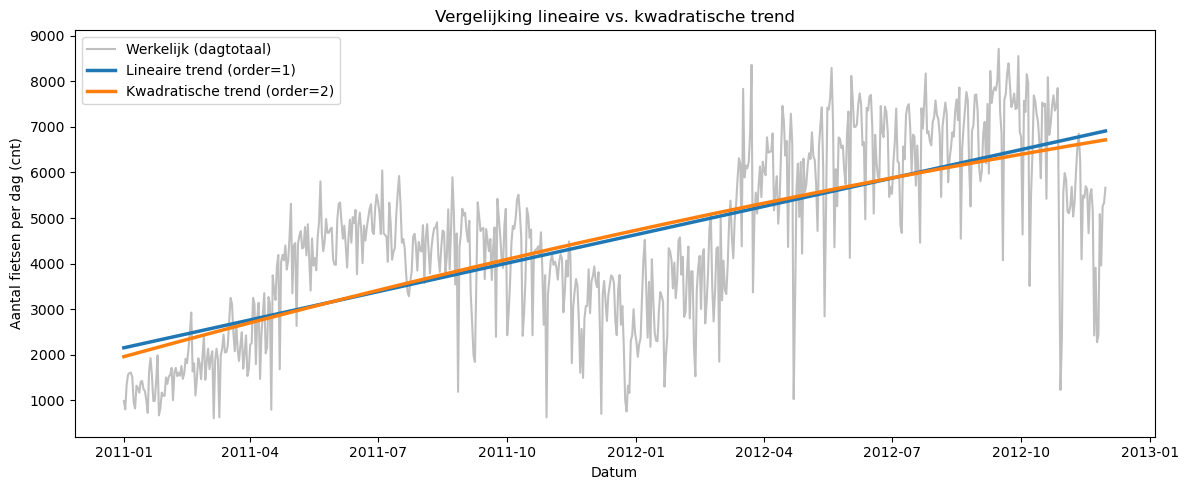

In [135]:
def plot_trends(ts_hourly):
    """Vergelijk een lineaire (order=1) en kwadratische (order=2) trend."""
    ts_daily = ts_hourly.resample("D").sum()

    plt.figure(figsize=(12, 5))
    plt.plot(ts_daily.index, ts_daily, color="0.75", label="Werkelijk (dagtotaal)")

    for order, label in [(1, "Lineaire trend (order=1)"), (2, "Kwadratische trend (order=2)")]:
        dp = DeterministicProcess(
            index=ts_daily.index,
            constant=True,
            order=order,
            drop=True,
        )
        X_trend = dp.in_sample()
        model = LinearRegression(fit_intercept=False).fit(X_trend, ts_daily)
        y_pred = pd.Series(model.predict(X_trend), index=ts_daily.index)
        plt.plot(y_pred.index, y_pred, linewidth=2.5, label=label)

    plt.title("Vergelijking lineaire vs. kwadratische trend")
    plt.xlabel("Datum")
    plt.ylabel("Aantal fietsen per dag (cnt)")
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_trends(ts_hourly)

Uit de grafiek blijkt dat de lineaire (`order=1`) en kwadratische (`order=2`) trend bijna exact gelijk lopen. Omdat een kwadratische trend weinig extra toevoegt en bij het voorspellen van de toekomst sneller kan doorschieten, kiezen we voor een lineaire trend (`order=1`) als feature.

## 2.3 Onderzoek naar seizoenspatronen met Fourier-analyse

Met een periodogram onderzoeken we welke seizoensfrequenties het sterkst aanwezig zijn in de uurlijkse tijdreeks. De hoogste pieken laten zien welke terugkerende patronen (zoals jaarlijks, wekelijks en dagelijks) we het beste kunnen vastleggen met Fourier-features (`CalendarFourier`).

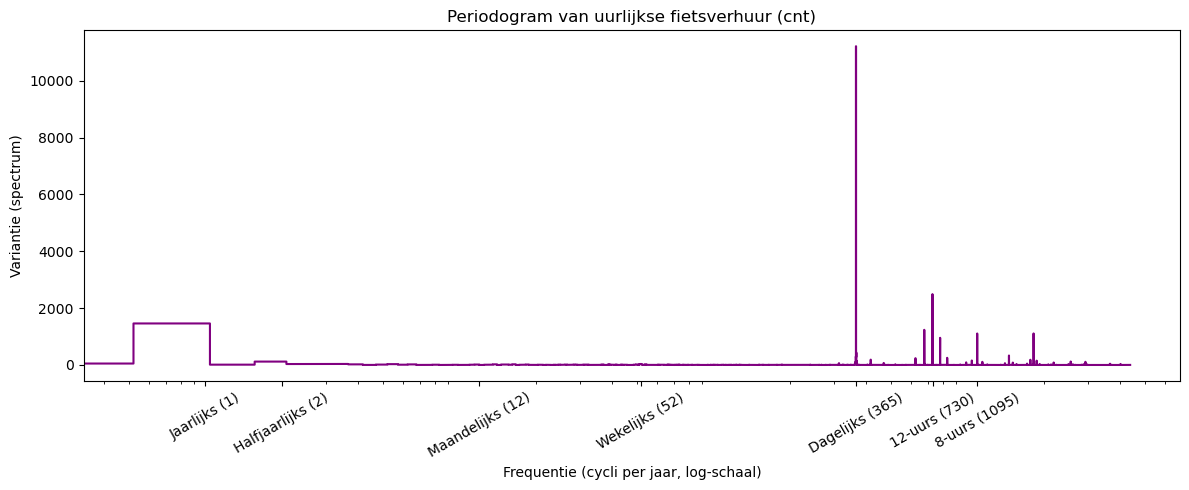

In [136]:
def plot_periodogram(ts_hourly):
    """Plot een periodogram van de uurlijkse tijdreeks om seizoensfrequenties te vinden."""
    # fs=24*365 zet de frequentie-as in cycli per jaar
    fs = 24 * 365
    frequencies, spectrum = periodogram(
        ts_hourly,
        fs=fs,
        detrend="linear",
        window="boxcar",
        scaling="spectrum",
    )

    plt.figure(figsize=(12, 5))
    plt.step(frequencies, spectrum, color="purple")
    plt.xscale("log")
    plt.xticks(
        [1, 2, 12, 52, 365, 730, 1095],
        [
            "Jaarlijks (1)",
            "Halfjaarlijks (2)",
            "Maandelijks (12)",
            "Wekelijks (52)",
            "Dagelijks (365)",
            "12-uurs (730)",
            "8-uurs (1095)",
        ],
        rotation=30,
    )
    plt.title("Periodogram van uurlijkse fietsverhuur (cnt)")
    plt.xlabel("Frequentie (cycli per jaar, log-schaal)")
    plt.ylabel("Variantie (spectrum)")
    plt.tight_layout()
    plt.show()


plot_periodogram(ts_hourly)

Uit het periodogram zijn de belangrijkste seizoenspatronen duidelijk te zien:
- De grootste piek ligt op het dagelijkse patroon (365), gevolgd door pieken op 12 uur (730) en 8 uur (1095). Dit komt door het grote verschil tussen dag en nacht en de twee spitsuren per dag.
- Daarnaast is er een duidelijke jaarlijkse piek (1) voor het verschil tussen zomer en winter.
- Op maandelijks niveau (12) is geen patroon zichtbaar.

Op basis hiervan nemen we straks jaarlijkse en dagelijkse Fourier-features mee in ons model.

## 2.4 Onderzoek naar cycli en autocorrelatie

Naast vaste seizoenspatronen kan het aantal verhuurde fietsen ook afhangen van de directe voorgaande uren (cycli en autocorrelatie). Met een ACF-plot (autocorrelatie) en PACF-plot (partiële autocorrelatie) over de laatste 48 uur onderzoeken we welke lag-features het meest informatief zijn.

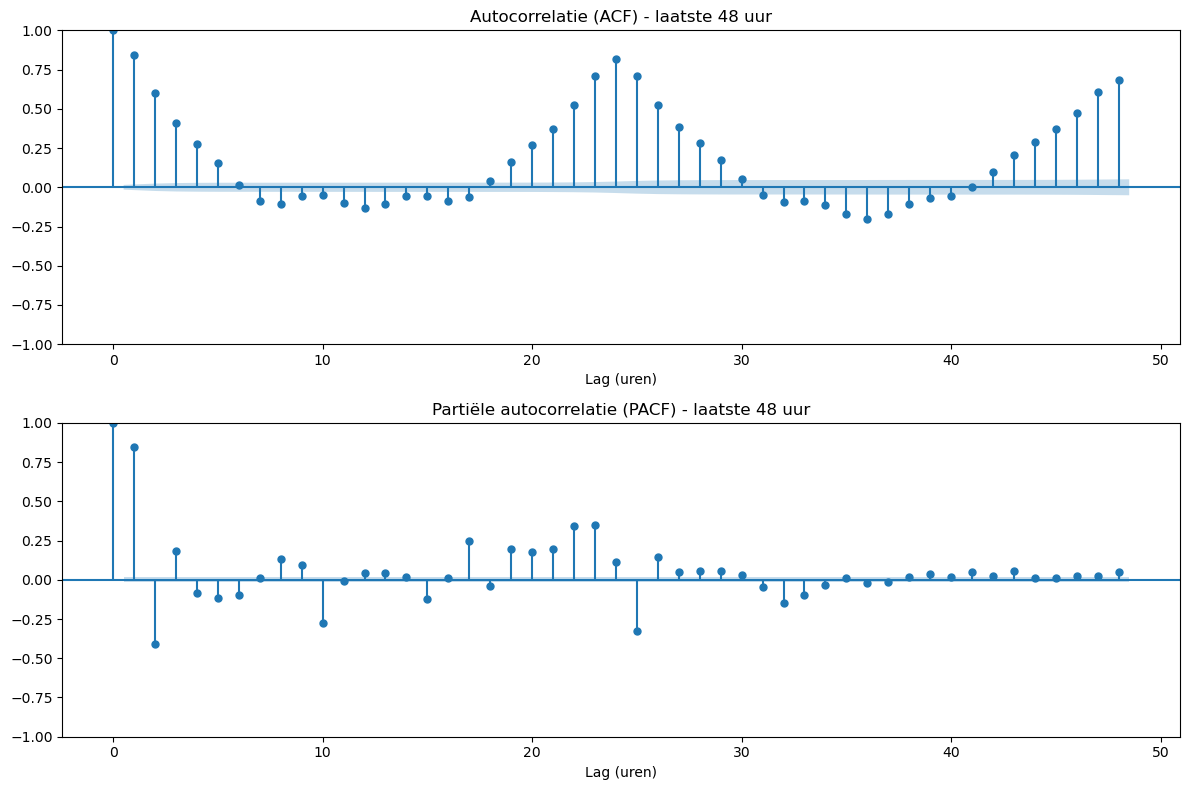

In [137]:
def plot_autocorrelation(ts_hourly, lags=48):
    """Plot de ACF en PACF van de uurlijkse tijdreeks."""
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    plot_acf(ts_hourly, lags=lags, ax=axes[0])
    axes[0].set_title("Autocorrelatie (ACF) - laatste 48 uur")
    axes[0].set_xlabel("Lag (uren)")

    plot_pacf(ts_hourly, lags=lags, ax=axes[1], method="ywm")
    axes[1].set_title("Partiële autocorrelatie (PACF) - laatste 48 uur")
    axes[1].set_xlabel("Lag (uren)")

    plt.tight_layout()
    plt.show()


plot_autocorrelation(ts_hourly, lags=48)

Uit de ACF- en PACF-plots blijkt het volgende:
- In de ACF zijn sterke pieken zichtbaar op lag 1 (ca. 0.84), lag 24 (ca. 0.82) en lag 48 (ca. 0.69). Dit laat een sterke 24-uurs cyclus zien.
- In de PACF steken vooral lag 1 (+0.85), lag 2 (-0.41), lag 22-23 (+0.35) en lag 25 (-0.33) duidelijk uit. Na lag 26 zwakt de directe autocorrelatie sterk af.

Belangrijke kanttekening voor het modelleren: omdat we in `test.csv` een volledige maand vooruit moeten voorspellen, zijn de werkelijke verhuuraantallen (`cnt`) van voorgaande uren daar niet beschikbaar. Directe `cnt`-lags gebruiken we daarom niet klakkeloos in de gewone regressiemodellen, maar deze analyse helpt ons wel bij het instellen van tijdseriemodellen (zoals SARIMAX) en eventuele lag-features van weersvariabelen.

## 2.5 Andere tijdsgebaseerde features en Feature Engineering class

Naast de trend en Fourier-features voegen we nog een aantal extra tijdsgebaseerde features toe op basis van de patronen uit opdracht 1:
- `is_workingday`: geeft aan of het een normale werkdag is (doordeweeks en geen feestdag).
- `is_rush_hour`: geeft de spitsuren op werkdagen aan (07:00-09:00 en 17:00-19:00).
- `is_night`: geeft de rustige nachturen aan (00:00-05:00).

We zetten alle tijdserie-features (lineaire trend, jaarlijkse en dagelijkse Fourier-termen en de extra tijdsfeatures) samen in een `TimeSeriesFeatureEngineer`-class. Zo kunnen we exact dezelfde transformatie later veilig op zowel de train- als de testset uitvoeren.

In [138]:
class TimeSeriesFeatureEngineer:
    """Voegt trend-, Fourier- en extra tijdsgebaseerde features toe."""

    def __init__(self, yearly_order=2, daily_order=3):
        self.yearly_order = yearly_order
        self.daily_order = daily_order
        self.dp_ = None
        self.train_index_ = None

    def fit(self, dataframe):
        """Fit DeterministicProcess op een gelijkmatige uurlijkse tijdlijn."""
        self.train_index_ = pd.date_range(
            start=dataframe.index.min(),
            end=dataframe.index.max(),
            freq="h",
        )

        fourier_yearly = CalendarFourier(freq="YE", order=self.yearly_order)
        fourier_daily = CalendarFourier(freq="D", order=self.daily_order)

        self.dp_ = DeterministicProcess(
            index=self.train_index_,
            constant=False,
            order=1,
            additional_terms=[fourier_yearly, fourier_daily],
            drop=True,
        )
        return self

    def transform(self, dataframe):
        """Voeg alle tijdserie-features toe aan een train- of test-DataFrame."""
        df_feat = dataframe.copy()

        # 1. Trend en Fourier-features ophalen (in-sample of out-of-sample)
        if df_feat.index.max() <= self.train_index_.max():
            dp_features = self.dp_.in_sample()
        else:
            steps = int(
                (df_feat.index.max() - self.train_index_.max()).total_seconds() // 3600
            )
            dp_features = pd.concat(
                [self.dp_.in_sample(), self.dp_.out_of_sample(steps=steps)]
            )

        # Koppel op exacte tijdstempels (werkt ook bij ontbrekende uren)
        dp_features = dp_features.reindex(df_feat.index)
        df_feat = pd.concat([df_feat, dp_features], axis=1)

        # 2. Extra tijdsgebaseerde features
        is_weekday = df_feat.index.dayofweek < 5
        df_feat["is_workingday"] = (is_weekday & (df_feat["holiday"] == 0)).astype(int)
        df_feat["is_rush_hour"] = (
            (df_feat["is_workingday"] == 1)
            & (df_feat.index.hour.isin([7, 8, 9, 17, 18, 19]))
        ).astype(int)
        df_feat["is_night"] = df_feat.index.hour.isin([0, 1, 2, 3, 4, 5]).astype(int)

        return df_feat


# Toepassen op de opgeschoonde trainingsdata
fe = TimeSeriesFeatureEngineer(yearly_order=2, daily_order=3)
df_features = fe.fit(df_clean).transform(df_clean)

print(f"Vorm voor feature engineering: {df_clean.shape}")
print(f"Vorm na feature engineering:   {df_features.shape}")
df_features.head()

Vorm voor feature engineering: (16637, 11)
Vorm na feature engineering:   (16637, 25)


,holiday,weathersit,temp,hum,windspeed,cnt,year,month,day_of_week,hour,...,"cos(2,freq=YE-DEC)","sin(1,freq=D)","cos(1,freq=D)","sin(2,freq=D)","cos(2,freq=D)","sin(3,freq=D)","cos(3,freq=D)",is_workingday,is_rush_hour,is_night
date_hour,,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.81,0.0,16,2011,1,5,0,...,1.000000,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,0,0,1
2011-01-01 01:00:00,0,1,0.22,0.80,0.0,40,2011,1,5,1,...,0.999999,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,0,0,1
2011-01-01 02:00:00,0,1,0.22,0.80,0.0,32,2011,1,5,2,...,0.999996,0.500000,0.866025,0.866025,5.000000e-01,1.000000e+00,6.123234e-17,0,0,1
2011-01-01 03:00:00,0,1,0.24,0.75,0.0,13,2011,1,5,3,...,0.999991,0.707107,0.707107,1.000000,6.123234e-17,7.071068e-01,-7.071068e-01,0,0,1
2011-01-01 04:00:00,0,1,0.24,0.75,0.0,1,2011,1,5,4,...,0.999984,0.866025,0.500000,0.866025,-5.000000e-01,1.224647e-16,-1.000000e+00,0,0,1


In [139]:
df_features.isna().sum().sum()

np.int64(0)

## 2.6 Samenvatting feature engineering

De dataset is uitgebreid van 11 naar 25 kolommen zonder ontbrekende waardes. Op basis van de analyses zijn de volgende tijdserie-features toegevoegd:
- Een lineaire trend (`order=1`) om de groei tussen 2011 en 2012 vast te leggen.
- Jaarlijkse (`order=2`) en dagelijkse (`order=3`) Fourier-features op basis van de pieken in het periodogram.
- Extra tijdsgebaseerde features: `is_workingday`, `is_rush_hour` en `is_night`.

In hoofdstuk 3 gaan we modellen trainen om te testen wat de daadwerkelijke invloed van deze features is op de voorspellingen, en kijken we of er aanpassingen nodig zijn.

# 3. Modelleren

## 3.1 Validatiestrategie en invloed van tijdserie-features

Omdat we werken met tijdreeksdata, gebruiken we `TimeSeriesSplit` (5 splits) in plaats van een willekeurige train/test-split. Zo traint het model altijd op het verleden en evalueert het op een later tijdstip om te zorgen dat er geen data leakage komt.

Als eerste stap testen we wat de invloed is van de nieuwe features uit hoofdstuk 2. We vergelijken de gemiddelde RMSE van twee baseline-modellen (`Ridge` en `RandomForestRegressor`) op de basisdataset (`df_clean`) tegen over de uitgebreide dataset (`df_features`).

In [140]:
def evaluate_feature_set(dataframe, models, n_splits=5):
    """Evalueer modellen met TimeSeriesSplit en bereken de gemiddelde RMSE."""
    X = dataframe.drop(columns=["cnt"])
    X = pd.get_dummies(X, columns=["weathersit"], drop_first=True)
    y = dataframe["cnt"]

    tscv = TimeSeriesSplit(n_splits=n_splits)
    results = {}

    for name, model in models.items():
        rmse_scores = []
        for train_idx, val_idx in tscv.split(X):
            X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

            model.fit(X_train, y_train)
            preds = np.clip(model.predict(X_val), 0, None)  # geen negatieve fietsen
            rmse_scores.append(root_mean_squared_error(y_val, preds))

        results[name] = round(np.mean(rmse_scores), 2)

    return results


baseline_models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

scores_basis = evaluate_feature_set(df_clean, baseline_models)
scores_features = evaluate_feature_set(df_features, baseline_models)

vergelijking = pd.DataFrame(
    {"Zonder tijdserie-features (RMSE)": scores_basis, "Met tijdserie-features (RMSE)": scores_features}
)
vergelijking["Verschil"] = (
    vergelijking["Met tijdserie-features (RMSE)"] - vergelijking["Zonder tijdserie-features (RMSE)"]
)
vergelijking

,Zonder tijdserie-features (RMSE),Met tijdserie-features (RMSE),Verschil
Ridge,156.46,196.20,39.74
Random Forest,78.31,75.63,-2.68


Uit de vergelijking vallen twee dingen op:
- **Random Forest** scoort veel beter dan Ridge (RMSE van 75.63 tegenover 156.46) en verbetert direct door de nieuwe tijdserie features (-2.68 RMSE). Dit komt doordat boommodellen niet lineaire interacties (zoals het verschil tussen spitsuren op werkdagen en weekenden) goed kunnen oppakken.
- Bij **Ridge** gaat de score juist achteruit (+39.74 RMSE) door de extra features. Omdat er in de eerste splits van `TimeSeriesSplit` nog geen heel jaar aan data zit, schiet een lineair model met al die overlappende tijdsfeatures te ver door bij het voorspellen.

Op basis hiervan richten we ons in de volgende stap vooral op boom- en boostingmodellen, en nemen we Ridge nog mee als lineaire referentie.

## 3.2 Meerdere modellen vergelijken

We bouwen een `ModelTrainer`-class om verschillende soorten modellen eerlijk met elkaar te vergelijken via `TimeSeriesSplit` (5 splits). We testen een lineair model (`Ridge`), twee bagging-modellen (`RandomForestRegressor` en `ExtraTreesRegressor`) en een boosting-model (`HistGradientBoostingRegressor`).

In [141]:
class ModelTrainer:
    """Traint en vergelijkt meerdere regressiemodellen met TimeSeriesSplit."""

    def __init__(self, models_dict, n_splits=5):
        self.models_dict = models_dict
        self.n_splits = n_splits
        self.results_ = {}
        self.best_model_name_ = None
        self.best_model_ = None

    def _prepare_xy(self, dataframe):
        X = dataframe.drop(columns=["cnt"])
        X = pd.get_dummies(X, columns=["weathersit"], drop_first=True)
        y = dataframe["cnt"]
        return X, y

    def evaluate(self, dataframe):
        """Evalueer alle modellen en bepaal het best presterende model."""
        X, y = self._prepare_xy(dataframe)
        tscv = TimeSeriesSplit(n_splits=self.n_splits)

        for name, model in self.models_dict.items():
            rmse_scores = []
            for train_idx, val_idx in tscv.split(X):
                X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
                y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

                model.fit(X_train, y_train)
                preds = np.clip(model.predict(X_val), 0, None)
                rmse_scores.append(root_mean_squared_error(y_val, preds))

            self.results_[name] = {
                "Gemiddelde RMSE": round(np.mean(rmse_scores), 2),
                "Std RMSE": round(np.std(rmse_scores), 2),
            }

        results_df = pd.DataFrame(self.results_).T.sort_values("Gemiddelde RMSE")
        self.best_model_name_ = results_df.index[0]
        self.best_model_ = self.models_dict[self.best_model_name_]
        return results_df


models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
}

trainer = ModelTrainer(models_dict=models, n_splits=5)
model_scores = trainer.evaluate(df_features)
print(f"Beste basismodel: {trainer.best_model_name_}")
model_scores

Beste basismodel: HistGradientBoosting


,Gemiddelde RMSE,Std RMSE
HistGradientBoosting,62.64,7.26
Extra Trees,72.91,14.81
Random Forest,75.63,9.99
Ridge,196.20,88.62


Uit de modelvergelijking komt `HistGradientBoosting` duidelijk als beste naar voren met een gemiddelde RMSE van 62.64 en de laagste standaardafwijking (7.26). Boosting modellen zijn bij dit soort tijdreeksdata met niet lineaire interacties (tijd, weer en spitsuren) merkbaar sterker dan bagging modellen (`Extra Trees`: 72.91, `Random Forest`: 75.63) en het lineaire model (`Ridge`: 196.20).

## 3.3 Iteratie en hyperparameter tuning

Als iteratieslag op hoofdstuk 2 onderzoeken we eerst of het toevoegen van lag-features op weersvariabelen (`temp_lag_1` en `hum_lag_1`) de score van `HistGradientBoosting` verder verbetert. Daarna tunen we de hyperparameters van het model met `GridSearchCV` en `TimeSeriesSplit`.

In [142]:
def add_weather_lags(dataframe):
    """Voeg 1-uurs lags van temperatuur en luchtvochtigheid toe."""
    df_lag = dataframe.copy()
    df_lag["temp_lag_1"] = df_lag["temp"].shift(1).bfill()
    df_lag["hum_lag_1"] = df_lag["hum"].shift(1).bfill()
    return df_lag


# 1. Test of weer-lags helpen bij HistGradientBoosting
df_features_v2 = add_weather_lags(df_features)

hgb_check = {"HistGradientBoosting": HistGradientBoostingRegressor(random_state=42)}
score_v1 = ModelTrainer(hgb_check, n_splits=5).evaluate(df_features).iloc[0, 0]
score_v2 = ModelTrainer(hgb_check, n_splits=5).evaluate(df_features_v2).iloc[0, 0]

print(f"HistGradientBoosting zonder weer-lags (RMSE): {score_v1}")
print(f"HistGradientBoosting met weer-lags (RMSE):    {score_v2}")

# Kies automatisch de beste dataset voor tuning
df_best = df_features_v2 if score_v2 < score_v1 else df_features
use_weather_lags = score_v2 < score_v1

# 2. Hyperparameter tuning met GridSearchCV en TimeSeriesSplit
X_best = pd.get_dummies(df_best.drop(columns=["cnt"]), columns=["weathersit"], drop_first=True)
y_best = df_best["cnt"]

param_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [200, 400],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [20, 50],
}

grid_search = GridSearchCV(
    estimator=HistGradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

grid_search.fit(X_best, y_best)

print(f"\nBeste parameters: {grid_search.best_params_}")
print(f"Beste CV RMSE na tuning: {-grid_search.best_score_:.2f}")

HistGradientBoosting zonder weer-lags (RMSE): 62.64
HistGradientBoosting met weer-lags (RMSE):    62.53

Beste parameters: {'learning_rate': 0.05, 'max_iter': 400, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}
Beste CV RMSE na tuning: 62.36


Uit de iteratieslag en tuning blijkt het volgende:
- Het toevoegen van de 1-uurs weer-lags (`temp_lag_1` en `hum_lag_1`) verlaagt de RMSE licht van 62.64 naar 62.53. We nemen deze features daarom mee in de definitieve dataset.
- Met `GridSearchCV` (5-fold `TimeSeriesSplit`) verbetert de score verder naar een gemiddelde RMSE van 62.36 met de parameters `learning_rate=0.05`, `max_iter=400`, `max_leaf_nodes=31` en `min_samples_leaf=20`.

## 3.4 Foutanalyse van het beste model

Om een beter beeld te krijgen van de prestaties van ons getunede `HistGradientBoosting`-model, visualiseren we de voorspellingen op de laatste validatiesplit (meest recente periode). We kijken naar een weekoverzicht van de werkelijke versus voorspelde verhuuraantallen en de verdeling van de fouten (residuen).